## 1. تثبيت الحزم وإعداد البيئة

In [ ]:
!pip -q install tiktoken matplotlib tensorflow tqdm

In [ ]:
import os
import sys
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tiktoken

torch.manual_seed(123)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. تحميل بيانات The Verdict

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"
DATA_PATH = "/content/the-verdict.txt"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Characters:", len(raw_text))
print(raw_text[:500])

Characters: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.)

"The height of his glory"--that was what the women called it. I can hear Mrs. Gideon Thwing--his last Chicago sitter--deploring his unaccountable abdication. "Of course it'


## 2b. تكبير حجم الداتا (The Verdict + كتب من Project Gutenberg)
الكتب دي public domain. تقدر تزوّد أو تشيل كتب من `EXTRA_BOOKS`. آخر 10% من كل كتاب بيتحط للـ validation.

In [ ]:
import re

EXTRA_BOOKS = {
    "pride-and-prejudice": "https://www.gutenberg.org/cache/epub/1342/pg1342.txt",
    "frankenstein":        "https://www.gutenberg.org/cache/epub/84/pg84.txt",
    "alice-in-wonderland": "https://www.gutenberg.org/cache/epub/11/pg11.txt",
    "moby-dick":           "https://www.gutenberg.org/cache/epub/2701/pg2701.txt",
    "dracula":             "https://www.gutenberg.org/cache/epub/345/pg345.txt",
    "sherlock-holmes":     "https://www.gutenberg.org/cache/epub/1661/pg1661.txt",
    "tale-of-two-cities":  "https://www.gutenberg.org/cache/epub/98/pg98.txt",
    "jane-eyre":           "https://www.gutenberg.org/cache/epub/1260/pg1260.txt",
    "dorian-gray":         "https://www.gutenberg.org/cache/epub/174/pg174.txt",
    "huckleberry-finn":    "https://www.gutenberg.org/cache/epub/76/pg76.txt",
}
UA = {"User-Agent": "Mozilla/5.0 (llm-from-scratch-notebook)"}


def clean_gutenberg(t):
    """بيشيل الهيدر والفوتر بتوع Project Gutenberg."""
    m = re.search(r"\*\*\* START OF .*?\*\*\*", t, re.S)
    if m:
        t = t[m.end():]
    e = t.find("*** END OF")
    if e != -1:
        t = t[:e]
    return t.strip()


def load_book(name, url):
    path = f"/content/{name}.txt"
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers=UA)
        with urllib.request.urlopen(req, timeout=60) as r:
            data = r.read().decode("utf-8-sig", errors="replace")
        with open(path, "w", encoding="utf-8") as f:
            f.write(data)
    with open(path, "r", encoding="utf-8-sig") as f:
        return clean_gutenberg(f.read())


with open(DATA_PATH, "r", encoding="utf-8") as f:
    verdict_text = f.read()

books = [("the-verdict", verdict_text)]
for name, url in EXTRA_BOOKS.items():
    try:
        books.append((name, load_book(name, url)))
    except Exception as e:
        print(f"تخطّيت {name}: {type(e).__name__}: {e}")

train_text, val_text = "", ""
for name, t in books:
    k = int(0.9 * len(t))
    train_text += t[:k] + " <|endoftext|> "
    val_text += t[k:] + " <|endoftext|> "
    print(f"{name:22s} {len(t):>10,} chars")

raw_text = train_text + val_text
print("\nTotal characters:", f"{len(raw_text):,}", "| books:", len(books))

the-verdict                20,479 chars
pride-and-prejudice       728,713 chars
frankenstein              419,336 chars
alice-in-wonderland       144,599 chars
moby-dick               1,218,973 chars
dracula                   845,889 chars
sherlock-holmes           562,202 chars
tale-of-two-cities        757,604 chars
jane-eyre               1,022,379 chars
dorian-gray               429,312 chars
huckleberry-finn          571,052 chars

Total characters: 6,720,868 | books: 11


## 3. Chapter 2 — Tokenization وDataset/DataLoader

In [ ]:
# GPT-2 byte-pair encoding tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

sample = "Hello, world!"
sample_ids = tokenizer.encode(sample)
print("Text:", sample)
print("Token IDs:", sample_ids)
print("Decoded:", tokenizer.decode(sample_ids))


class GPTDatasetV1(Dataset):
    """Creates input/target token chunks for next-token prediction."""
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1:i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk, dtype=torch.long))
            self.target_ids.append(torch.tensor(target_chunk, dtype=torch.long))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128,
                         shuffle=True, drop_last=True, num_workers=0):
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      drop_last=drop_last, num_workers=num_workers)


demo_loader = create_dataloader_v1(raw_text, batch_size=2, max_length=8, stride=4)
demo_x, demo_y = next(iter(demo_loader))
print("Input batch:", demo_x.shape)
print("Target batch:", demo_y.shape)
print("First input IDs:", demo_x[0].tolist())
print("First target IDs:", demo_y[0].tolist())

Text: Hello, world!
Token IDs: [15496, 11, 995, 0]
Decoded: Hello, world!
Input batch: torch.Size([2, 8])
Target batch: torch.Size([2, 8])
First input IDs: [284, 423, 2147, 475, 8509, 290, 198, 7050]
First target IDs: [423, 2147, 475, 8509, 290, 198, 7050, 284]


## 4. Chapter 3 — Attention Mechanisms

In [ ]:
class SelfAttention_v1(nn.Module):
    """Basic self-attention, primarily for understanding the calculation."""
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value
        attention_scores = queries @ keys.T
        attention_weights = torch.softmax(attention_scores / keys.shape[-1]**0.5, dim=-1)
        return attention_weights @ values


class SelfAttention_v2(nn.Module):
    """Self-attention with trainable Linear layers."""
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attention_scores = queries @ keys.transpose(-2, -1)
        attention_weights = torch.softmax(attention_scores / keys.shape[-1]**0.5, dim=-1)
        return attention_weights @ values


class CausalAttention(nn.Module):
    """Masks future tokens so a position cannot attend to later positions."""
    def __init__(self, d_in, d_out, context_length, dropout=0.0, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        scores = queries @ keys.transpose(1, 2)
        scores = scores.masked_fill(self.mask[:num_tokens, :num_tokens].bool(), -torch.inf)
        weights = torch.softmax(scores / keys.shape[-1]**0.5, dim=-1)
        weights = self.dropout(weights)
        return weights @ values


class MultiHeadAttentionWrapper(nn.Module):
    """Concatenates multiple independent causal-attention heads."""
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList([
            CausalAttention(d_in, d_out, context_length, dropout, qkv_bias)
            for _ in range(num_heads)
        ])

    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)


class MultiHeadAttention(nn.Module):
    """Efficient multi-head causal attention, as used by GPT."""
    def __init__(self, d_in, d_out, context_length, num_heads, dropout=0.0, qkv_bias=False):
        super().__init__()
        if d_out % num_heads != 0:
            raise ValueError("d_out must be divisible by num_heads")
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        queries = self.W_query(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        values = self.W_value(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)

        scores = queries @ keys.transpose(2, 3)
        scores = scores.masked_fill(self.mask[:num_tokens, :num_tokens].bool(), -torch.inf)
        weights = torch.softmax(scores / self.head_dim**0.5, dim=-1)
        weights = self.dropout(weights)

        context = (weights @ values).transpose(1, 2).contiguous()
        context = context.view(b, num_tokens, self.d_out)
        return self.out_proj(context)


# Quick shape test
toy_x = torch.rand(2, 6, 32)
toy_att = MultiHeadAttention(32, 32, context_length=6, num_heads=4, dropout=0.1)
print("Multi-head attention output:", toy_att(toy_x).shape)

Multi-head attention output: torch.Size([2, 6, 32])


## 5. Chapter 4 — GPT building blocks: LayerNorm, GELU, FeedForward, TransformerBlock, GPTModel

In [ ]:
class LayerNorm(nn.Module):
    """Layer normalization with learnable scale and shift."""
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


class GELU(nn.Module):
    """GELU activation approximation used in the book."""
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi, device=x.device)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        if seq_len > self.pos_emb.num_embeddings:
            raise ValueError(f"Sequence length {seq_len} exceeds context length {self.pos_emb.num_embeddings}")
        tok_embeds = self.tok_emb(in_idx)
        pos_ids = torch.arange(seq_len, device=in_idx.device)
        pos_embeds = self.pos_emb(pos_ids)
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": True
}

TINY_CONFIG = {
    "vocab_size": 50257, "context_length": 256, "emb_dim": 64,
    "n_heads": 4, "n_layers": 2, "drop_rate": 0.0, "qkv_bias": True
}
tiny_model = GPTModel(TINY_CONFIG)
tiny_ids = torch.randint(0, TINY_CONFIG["vocab_size"], (2, 10))
print("Tiny GPT output shape:", tiny_model(tiny_ids).shape)

Tiny GPT output shape: torch.Size([2, 10, 50257])


## 6. Chapter 5 — تجهيز train/validation DataLoader

In [ ]:

BATCH_SIZE = 4   # لو طلع Out Of Memory قلّله لـ 2
MAX_LENGTH = 256
STRIDE = 256     # من غير overlap بين الـ windows

train_loader = create_dataloader_v1(
    train_text, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, stride=STRIDE,
    shuffle=True, drop_last=True
)
val_loader = create_dataloader_v1(
    val_text, batch_size=BATCH_SIZE, max_length=MAX_LENGTH, stride=STRIDE,
    shuffle=False, drop_last=False
)
print("Train batches:", len(train_loader), "Validation batches:", len(val_loader))
n_train_tok = len(tokenizer.encode(train_text, allowed_special={"<|endoftext|>"}))
n_val_tok = len(tokenizer.encode(val_text, allowed_special={"<|endoftext|>"}))
print(f"Train tokens: {n_train_tok:,} | Validation tokens: {n_val_tok:,}")


Train batches: 1613 Validation batches: 183
Train tokens: 1,652,102 | Validation tokens: 187,079


## 7. Loss, evaluation, text generation

In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    return nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())


@torch.no_grad()
def calc_loss_loader(data_loader, model, device, num_batches=None):
    model.eval()
    if len(data_loader) == 0:
        return float("nan")
    n = len(data_loader) if num_batches is None else min(num_batches, len(data_loader))
    total_loss = 0.0
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i >= n:
            break
        total_loss += calc_loss_batch(input_batch, target_batch, model, device).item()
    return total_loss / n


def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    return torch.tensor(encoded, dtype=torch.long).unsqueeze(0)


def token_ids_to_text(token_ids, tokenizer):
    return tokenizer.decode(token_ids.squeeze(0).tolist())


@torch.no_grad()
def generate_text_simple(model, idx, max_new_tokens, context_size):
    model.eval()
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        logits = model(idx_cond)
        logits = logits[:, -1, :]
        idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)
    return idx


demo_model = GPTModel(TINY_CONFIG).to(device)
print("Initial train loss:", calc_loss_loader(train_loader, demo_model, device, num_batches=2))
print("Initial val loss:", calc_loss_loader(val_loader, demo_model, device, num_batches=2))
prompt = "Every effort moves you"
idx = text_to_token_ids(prompt, tokenizer).to(device)
out = generate_text_simple(demo_model, idx, max_new_tokens=20, context_size=TINY_CONFIG["context_length"])
print(token_ids_to_text(out, tokenizer))

Initial train loss: 10.979252815246582
Initial val loss: 10.97942590713501
Every effort moves you Mazdaaffectedbenef Tradableminster regiment LentASS concurrent Xuan........................income 263 ForestryServalmostpm124 Forumoths


## 8. تدريب نموذج من البداية (Chapter 5 — مثال تعليمي صغير)

step 001 | train loss 10.9699 | val loss 10.9658
step 005 | train loss 10.9021 | val loss 10.9072
step 010 | train loss 10.7988 | val loss 10.8208
step 015 | train loss 10.6518 | val loss 10.7076
step 020 | train loss 10.5007 | val loss 10.5538


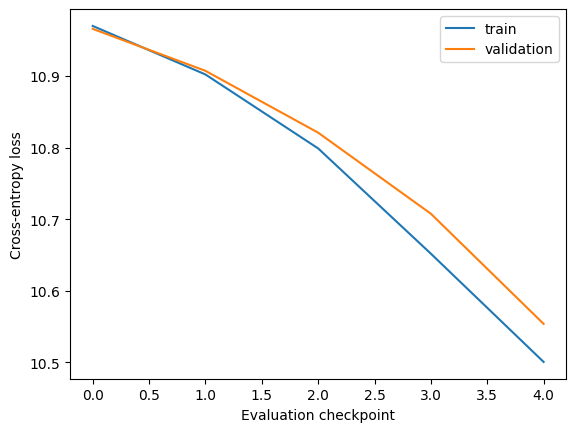

In [ ]:

optimizer = torch.optim.AdamW(demo_model.parameters(), lr=4e-4, weight_decay=0.1)
NUM_EPOCHS = 1
MAX_STEPS = 20
step = 0
train_loss_history, val_loss_history = [], []

for epoch in range(NUM_EPOCHS):
    demo_model.train()
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        loss = calc_loss_batch(input_batch, target_batch, demo_model, device)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(demo_model.parameters(), max_norm=1.0)
        optimizer.step()
        step += 1

        if step == 1 or step % 5 == 0:
            tr_loss = calc_loss_loader(train_loader, demo_model, device, num_batches=2)
            va_loss = calc_loss_loader(val_loader, demo_model, device, num_batches=2)
            train_loss_history.append(tr_loss)
            val_loss_history.append(va_loss)
            print(f"step {step:03d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f}")

        if step >= MAX_STEPS:
            break
    if step >= MAX_STEPS:
        break

plt.plot(train_loss_history, label="train")
plt.plot(val_loss_history, label="validation")
plt.xlabel("Evaluation checkpoint")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

## 9. تحميل أوزان GPT-2 Small (124M) من المصدر الرسمي

In [ ]:

if not os.path.exists("/content/LLMs-from-scratch"):
    !git clone --depth 1 https://github.com/rasbt/LLMs-from-scratch.git /content/LLMs-from-scratch

sys.path.insert(0, "/content/LLMs-from-scratch/ch05/01_main-chapter-code")
from gpt_download import download_and_load_gpt2

settings, params = download_and_load_gpt2(model_size="124M", models_dir="/content/gpt2")
print(settings)

Cloning into '/content/LLMs-from-scratch'...
remote: Enumerating objects: 442, done.
remote: Counting objects: 100% (442/442), done.
remote: Compressing objects: 100% (346/346), done.
remote: Total 442 (delta 112), reused 368 (delta 83), pack-reused 0 (from 0)
Receiving objects: 100% (442/442), 2.29 MiB | 19.19 MiB/s, done.
Resolving deltas: 100% (112/112), done.


checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 69.8kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 3.61MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 192kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [00:36<00:00, 13.6MiB/s]
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 9.65MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 1.85MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.76MiB/s]


{'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}


In [ ]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch: {left.shape} vs {right.shape}")
    return nn.Parameter(torch.tensor(right, dtype=torch.float32))


def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte"])

    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(params["blocks"][b]["attn"]["c_attn"]["w"], 3, axis=-1)
        q_b, k_b, v_b = np.split(params["blocks"][b]["attn"]["c_attn"]["b"], 3, axis=-1)

        gpt.trf_blocks[b].att.W_query.weight = assign(gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(gpt.trf_blocks[b].att.W_value.weight, v_w.T)
        gpt.trf_blocks[b].att.W_query.bias = assign(gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params["blocks"][b]["attn"]["c_proj"]["w"].T
        )
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params["blocks"][b]["attn"]["c_proj"]["b"]
        )

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params["blocks"][b]["mlp"]["c_fc"]["w"].T
        )
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params["blocks"][b]["mlp"]["c_fc"]["b"]
        )
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params["blocks"][b]["mlp"]["c_proj"]["w"].T
        )
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params["blocks"][b]["mlp"]["c_proj"]["b"]
        )

        gpt.trf_blocks[b].norm1.scale = assign(gpt.trf_blocks[b].norm1.scale, params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(gpt.trf_blocks[b].norm1.shift, params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(gpt.trf_blocks[b].norm2.scale, params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(gpt.trf_blocks[b].norm2.shift, params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = gpt.tok_emb.weight


gpt2_model = GPTModel(GPT_CONFIG_124M).to(device)
load_weights_into_gpt(gpt2_model, params)
gpt2_model.to(device)
gpt2_model.eval()
print("GPT-2 Small weights loaded.")
print("Parameters:", f"{sum(p.numel() for p in gpt2_model.parameters()):,}")

GPT-2 Small weights loaded.
Parameters: 124,439,808


## 10. اختبار GPT-2 ثم حفظ نسخة من الأوزان

In [ ]:
prompt = "Every effort moves you"
idx = text_to_token_ids(prompt, tokenizer).to(device)
out = generate_text_simple(
    gpt2_model, idx, max_new_tokens=40,
    context_size=GPT_CONFIG_124M["context_length"]
)
print(token_ids_to_text(out, tokenizer))

save_path = "/content/gpt2_124M_pretrained.pth"
torch.save({
    "model_state_dict": gpt2_model.state_dict(),
    "config": GPT_CONFIG_124M
}, save_path)
print("Saved checkpoint:", save_path)


from google.colab import files
files.download(save_path)

Every effort moves you forward.

The first step is to understand the importance of your work.

The second step is to understand the importance of your work.

The third step is to understand the importance
Saved checkpoint: /content/gpt2_124M_pretrained.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. تدريب تكميلي لأوزان GPT-2 على The Verdict + كتب Gutenberg

Before training | val loss 3.9491 | perplexity 51.9
Sample: Every effort moves you forward.  The first step is to understand the importance of your work.  The second step is to understand the importance of your work.  The third step is to understand the importance 



Epoch 1/2:   0%|          | 0/1613 [00:00<?, ?it/s]

  step 00100 | train 3.701 | val 3.318 | val ppl 27.6
  step 00200 | train 3.636 | val 3.269 | val ppl 26.3
  step 00300 | train 3.552 | val 3.236 | val ppl 25.4
  step 00400 | train 3.507 | val 3.201 | val ppl 24.5
  step 00500 | train 3.480 | val 3.177 | val ppl 24.0
  step 00600 | train 3.464 | val 3.167 | val ppl 23.7
  step 00700 | train 3.425 | val 3.162 | val ppl 23.6
  step 00800 | train 3.443 | val 3.140 | val ppl 23.1
  step 00900 | train 3.405 | val 3.117 | val ppl 22.6
  step 01000 | train 3.416 | val 3.111 | val ppl 22.4
  step 01100 | train 3.413 | val 3.093 | val ppl 22.0
  step 01200 | train 3.426 | val 3.099 | val ppl 22.2
  step 01300 | train 3.397 | val 3.093 | val ppl 22.0
  step 01400 | train 3.406 | val 3.097 | val ppl 22.1
  step 01500 | train 3.388 | val 3.080 | val ppl 21.7
  step 01600 | train 3.297 | val 3.075 | val ppl 21.7

>>> Epoch 1 done in 10.0 min | avg train loss 3.459 | full val loss 3.307 (ppl 27.3)
Sample: Every effort moves you, and you are not to

Epoch 2/2:   0%|          | 0/1613 [00:00<?, ?it/s]

  step 01700 | train 3.251 | val 3.065 | val ppl 21.4
  step 01800 | train 3.157 | val 3.069 | val ppl 21.5
  step 01900 | train 3.224 | val 3.055 | val ppl 21.2
  step 02000 | train 3.209 | val 3.061 | val ppl 21.4
  step 02100 | train 3.217 | val 3.064 | val ppl 21.4
  step 02200 | train 3.254 | val 3.047 | val ppl 21.1
  step 02300 | train 3.197 | val 3.047 | val ppl 21.1
  step 02400 | train 3.177 | val 3.045 | val ppl 21.0
  step 02500 | train 3.161 | val 3.048 | val ppl 21.1
  step 02600 | train 3.199 | val 3.036 | val ppl 20.8
  step 02700 | train 3.226 | val 3.035 | val ppl 20.8
  step 02800 | train 3.202 | val 3.032 | val ppl 20.7
  step 02900 | train 3.202 | val 3.035 | val ppl 20.8
  step 03000 | train 3.200 | val 3.030 | val ppl 20.7
  step 03100 | train 3.212 | val 3.029 | val ppl 20.7
  step 03200 | train 3.197 | val 3.019 | val ppl 20.5

>>> Epoch 2 done in 10.0 min | avg train loss 3.203 | full val loss 3.258 (ppl 26.0)
Sample: Every effort moves you, and you are wonder

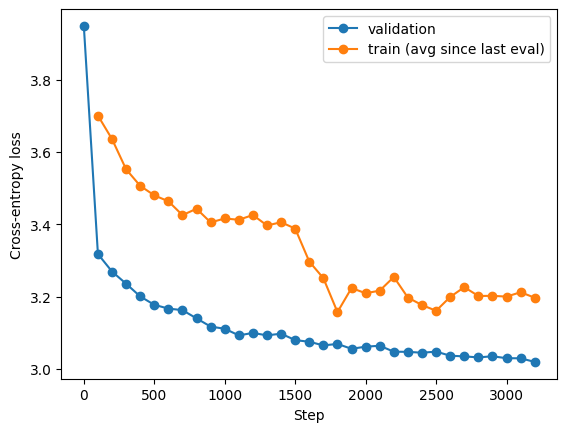

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import math
import time
from tqdm.auto import tqdm

NUM_EPOCHS_GPT2 = 2      # غيّرها زي ما تحب
EVAL_EVERY = 100         # كل كام step نقيس الـ validation loss
EVAL_BATCHES = 20        # عدد batches الـ validation في القياس الدوري
LR = 5e-5
PROMPT = "Every effort moves you"
continued_path = "/content/gpt2_124M_the_verdict_continued_pretraining.pth"


def sample_text(model, prompt, n=40):
    ids = text_to_token_ids(prompt, tokenizer).to(device)
    out = generate_text_simple(model, ids, max_new_tokens=n,
                               context_size=GPT_CONFIG_124M["context_length"])   # بيحوّل الموديل لـ eval
    model.train()
    return token_ids_to_text(out, tokenizer).replace("\n", " ")


# قبل التدريب: baseline بأوزان GPT-2 الأصلية
base_val = calc_loss_loader(val_loader, gpt2_model, device, num_batches=EVAL_BATCHES)
print(f"Before training | val loss {base_val:.4f} | perplexity {math.exp(base_val):.1f}")
print("Sample:", sample_text(gpt2_model, PROMPT), "\n")

gpt2_model.train()
optimizer = torch.optim.AdamW(gpt2_model.parameters(), lr=LR, weight_decay=0.1)

step, tokens_seen, t0 = 0, 0, time.time()
hist_step, hist_train, hist_val = [0], [float("nan")], [base_val]
recent = []

for epoch in range(NUM_EPOCHS_GPT2):
    gpt2_model.train()
    ep_start, ep_sum, ep_n = time.time(), 0.0, 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_GPT2}")

    for input_batch, target_batch in pbar:
        optimizer.zero_grad(set_to_none=True)
        loss = calc_loss_batch(input_batch, target_batch, gpt2_model, device)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gpt2_model.parameters(), max_norm=1.0)
        optimizer.step()

        step += 1
        tokens_seen += input_batch.numel()
        ep_sum += loss.item(); ep_n += 1
        recent.append(loss.item())
        pbar.set_postfix(loss=f"{loss.item():.3f}", tok_per_s=f"{tokens_seen / (time.time() - t0):,.0f}")

        if step % EVAL_EVERY == 0:
            va = calc_loss_loader(val_loader, gpt2_model, device, num_batches=EVAL_BATCHES)
            gpt2_model.train()                      # calc_loss_loader بيحوّل الموديل لـ eval
            tr = sum(recent) / len(recent); recent = []
            hist_step.append(step); hist_train.append(tr); hist_val.append(va)
            tqdm.write(f"  step {step:05d} | train {tr:.3f} | val {va:.3f} | val ppl {math.exp(va):.1f}")

    va_full = calc_loss_loader(val_loader, gpt2_model, device)      # validation كامل في آخر كل epoch
    print(f"\n>>> Epoch {epoch + 1} done in {(time.time() - ep_start) / 60:.1f} min | "
          f"avg train loss {ep_sum / ep_n:.3f} | full val loss {va_full:.3f} (ppl {math.exp(va_full):.1f})")
    print("Sample:", sample_text(gpt2_model, PROMPT), "\n")
    torch.save({"model_state_dict": gpt2_model.state_dict(), "config": GPT_CONFIG_124M,
                "steps": step, "epoch": epoch + 1}, continued_path)
    print(f"(checkpoint saved -> {continued_path})\n")

print(f"Training finished in {(time.time() - t0) / 60:.1f} min | {step} steps | {tokens_seen:,} tokens")

plt.plot(hist_step, hist_val, marker="o", label="validation")
plt.plot(hist_step[1:], hist_train[1:], marker="o", label="train (avg since last eval)")
plt.xlabel("Step"); plt.ylabel("Cross-entropy loss"); plt.legend(); plt.show()

files.download(continued_path)


In [ ]:
from google.colab import files

files.download('/content/gpt2_124M_the_verdict_continued_pretraining.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for root, dirs, filenames in os.walk("/content"):
    for filename in filenames:
        if filename.endswith(".pth"):
            print(os.path.join(root, filename))

/content/gpt2_124M_pretrained.pth
/content/gpt2_124M_the_verdict_continued_pretraining.pth


In [ ]:
import os

file_path = "/content/gpt2_124M_the_verdict_continued_pretraining.pth"

if os.path.exists(file_path):
    size_mb = os.path.getsize(file_path) / (1024 ** 2)
    print(f"File size: {size_mb:.2f} MB")
else:
    print("الملف غير موجود!")

File size: 522.78 MB
